# Oficina de Exploração do Saeb 2023 — Pernambuco (9º Ano EF)

## 1. Retomada da Oficina do Censo Escolar 2023
- **Pergunta anterior (Censo Escolar — *Escada Tecnológica*):** *Como se distribui a infraestrutura digital declarada pelas escolas (internet banda larga, computadores/tablets e laboratório) nas redes públicas e privadas?*
- **O que o Censo Escolar já respondeu:** mapeou os recursos físicos e tecnológicos disponíveis **na escola**, por localização e dependência administrativa.
- **O que ainda faltava:** o Censo Escolar não informa o **contexto domiciliar do estudante** (acesso à internet em casa, presença dos pais na residência, nível socioeconômico individual) nem o **desempenho acadêmico medido em prova**.
- **Ajuste após conhecer o Saeb 2023:** a investigação foi ampliada para analisar como a **proficiência em Matemática** (`PROFICIENCIA_MT_SAEB`) se relaciona com a **presença dos pais em casa** (`TX_RESP_Q07a`, `TX_RESP_Q07b`), a **conectividade domiciliar** (`TX_RESP_Q13b`) e o **nível socioeconômico** (`NU_TIPO_NIVEL_INSE`) no 9º ano de Pernambuco.

## 2. Investigação dos Arquivos do Saeb 2023
- **Arquivo:** `TS_ALUNO_9EF.csv` · **Edição:** Saeb 2023 · **Etapa:** 9º ano do Ensino Fundamental (`ID_SERIE = 9`) · **Território:** Pernambuco (`ID_UF = 26`, Região Nordeste) · **Unidade:** `1 linha = 1 estudante`.
- **O que traz que não existe no Censo Escolar:** respostas individuais do questionário do estudante sobre sua casa e família, proficiência em Matemática (escala Saeb) e campos técnicos de amostragem (`PESO_ALUNO_MT`, `IN_INSE`, `IN_SITUACAO_CENSO`).
- **Compatibilidade com o Censo Escolar 2023:** `ID_UF` (`26`), `ID_LOCALIZACAO` (`1`=Urbana, `2`=Rural) e `IN_PUBLICA` batem; porém, por LGPD, `ID_ESCOLA` e `ID_MUNICIPIO` no Saeb são **máscaras fictícias iniciadas por `6`** (não permitem junção direta por escola/município com `CO_ENTIDADE`/`CO_MUNICIPIO` do Censo).

In [45]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

UF_CODIGO, UF_SIGLA, UF_NOME = 26, "PE", "Pernambuco"
BASE_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "oficina_saeb_2023" else os.path.abspath(".")
PATH_SAEB_9EF = os.path.join(BASE_DIR, "MICRODADOS_SAEB_2023", "DADOS", "TS_ALUNO_9EF.csv")
DIR_SAIDAS = os.path.join(BASE_DIR, "oficina_saeb_2023", "saidas")
os.makedirs(DIR_SAIDAS, exist_ok=True)

COLS = [
    "ID_SAEB", "ID_UF", "ID_MUNICIPIO", "ID_ESCOLA", "IN_PUBLICA", "ID_LOCALIZACAO",
    "ID_ALUNO", "IN_SITUACAO_CENSO", "IN_PREENCHIMENTO_QUESTIONARIO",
    "PESO_ALUNO_MT", "IN_INSE", "NU_TIPO_NIVEL_INSE",
    "TX_RESP_Q07a", "TX_RESP_Q07b", "TX_RESP_Q13b",
    "PROFICIENCIA_MT_SAEB"
]

df = pd.concat(
    [c[c["ID_UF"] == UF_CODIGO] for c in pd.read_csv(PATH_SAEB_9EF, sep=";", encoding="latin1", usecols=COLS, chunksize=250_000, low_memory=False)],
    ignore_index=True
)

mask_inse_valido = df["IN_INSE"] == 1
mask_q07_valido = df["TX_RESP_Q07a"].isin(["A", "B"]) & df["TX_RESP_Q07b"].isin(["A", "B"])

ficha = pd.DataFrame([
    ("Edição / Etapa / Território", "Saeb 2023 · 9º ano EF · Pernambuco (ID_UF = 26)"),
    ("Total de registros (1 linha = 1 estudante)", f"{len(df):,}"),
    ("Escolas / Municípios distintos (mascarados)", f"{df['ID_ESCOLA'].nunique():,} escolas · {df['ID_MUNICIPIO'].nunique():,} municípios"),
    ("Rede (IN_PUBLICA)", f"Pública: {(df['IN_PUBLICA']==1).sum():,} | Privada (amostral): {(df['IN_PUBLICA']==0).sum():,}"),
    ("Localização (ID_LOCALIZACAO)", f"Urbana: {(df['ID_LOCALIZACAO']==1).sum():,} | Rural: {(df['ID_LOCALIZACAO']==2).sum():,}"),
    ("Consistentes com Censo 2023 (IN_SITUACAO_CENSO=1)", f"{(df['IN_SITUACAO_CENSO']==1).sum():,} ({(df['IN_SITUACAO_CENSO']==1).mean()*100:.1f}%)"),
    ("Proficiência válida em Matemática", f"{df['PROFICIENCIA_MT_SAEB'].notna().sum():,} ({df['PROFICIENCIA_MT_SAEB'].notna().mean()*100:.1f}%)"),
    ("INSE válido (IN_INSE = 1)", f"{mask_inse_valido.sum():,} ({mask_inse_valido.mean()*100:.1f}%)"),
    ("Q07a e Q07b válidos / Peso MT > 0", f"{mask_q07_valido.sum():,} / {(df['PESO_ALUNO_MT'].fillna(0)>0).sum():,}"),
], columns=["Item", "Recorte Pernambuco (PE)"])

display(ficha)

,Item,Recorte Pernambuco (PE)
0,Edição / Etapa / Território,Saeb 2023 · 9º ano EF · Pernambuco (ID_UF = 26)
1,Total de registros (1 linha = 1 estudante),"109,542"
2,Escolas / Municípios distintos (mascarados),"1,450 escolas · 185 municípios"
3,Rede (IN_PUBLICA),"Pública: 107,556 | Privada (amostral): 1,986"
4,Localização (ID_LOCALIZACAO),"Urbana: 91,505 | Rural: 18,037"
5,Consistentes com Censo 2023 (IN_SITUACAO_CENSO=1),"108,470 (99.0%)"
6,Proficiência válida em Matemática,"96,313 (87.9%)"
7,INSE válido (IN_INSE = 1),"91,362 (83.4%)"
8,Q07a e Q07b válidos / Peso MT > 0,"84,700 / 95,947"


---
## 3. As 5 Variáveis Selecionadas (`TS_ALUNO_9EF.csv`)

| Coluna escolhida | O que registra | Valores válidos e códigos especiais (Dicionário Saeb 2023) |
|---|---|---|
| `TX_RESP_Q07a` | Normalmente, quem mora na sua casa? — Mãe(s) ou madrasta(s) | **Válidos:** `A` = Não; `B` = Sim · **Especiais:** `.` = Branco; `*` = Nulo; vazio (`NaN`) |
| `TX_RESP_Q07b` | Normalmente, quem mora na sua casa? — Pai(s) ou padrasto(s) | **Válidos:** `A` = Não; `B` = Sim · **Especiais:** `.` = Branco; `*` = Nulo; vazio (`NaN`) |
| `TX_RESP_Q13b` | Na sua casa tem: Rede Wi-Fi | **Válidos:** `A` = Não; `B` = Sim · **Especiais:** `.` = Branco; `*` = Nulo; vazio (`NaN`) |
| `NU_TIPO_NIVEL_INSE` | Classificação do Indicador de Nível Socioeconômico em 8 grupos | **Válidos:** `1` (Nível I, mais baixo) a `8` (Nível VIII, mais alto) quando `IN_INSE = 1` · **Especial:** no CSV bruto, os `18.180` alunos com `IN_INSE = 0` (não calculado) aparecem codificados como `1` e são excluídos do denominador válido |
| `PROFICIENCIA_MT_SAEB` | Proficiência em Matemática (escala Saeb: média 250, DP 50) | **Válidos:** numérico contínuo (presentes, ≥3 itens, consistentes com Censo) · **Especial:** `NaN` = ausente/inválido |

In [46]:
# 4.1 Frequências das variáveis categóricas (denominador = respostas válidas; ausências separadas)
LEGENDAS = {
    "TX_RESP_Q07a": ("Mora com mãe ou madrasta", {"A": "Não", "B": "Sim"}),
    "TX_RESP_Q07b": ("Mora com pai ou padrasto", {"A": "Não", "B": "Sim"}),
    "TX_RESP_Q13b": ("Rede Wi-Fi em casa", {"A": "Não", "B": "Sim"}),
}

rows_cat = []
for col, (desc, mapa) in LEGENDAS.items():
    s = df[col]
    n_val = int(s.isin(mapa.keys()).sum())
    for k, rotulo in mapa.items():
        qtd = int((s == k).sum())
        rows_cat.append({
            "Variável": col, "Descrição": desc, "Tipo": "Válido", "Categoria": f"{k} - {rotulo}",
            "Quantidade": qtd, "% sobre válidos": round(qtd / n_val * 100, 1), "Denominador válido": n_val
        })
    for k, rotulo in [(".", "Branco"), ("*", "Nulo")]:
        qtd = int((s == k).sum())
        rows_cat.append({
            "Variável": col, "Descrição": desc, "Tipo": "Especial/Ausência", "Categoria": f"{k} - {rotulo}",
            "Quantidade": qtd, "% sobre válidos": np.nan, "Denominador válido": n_val
        })

# Inclui NU_TIPO_NIVEL_INSE com ausências (IN_INSE = 0) registradas separadamente
n_inse_val = int(mask_inse_valido.sum())
romanos = {1: "Nível I", 2: "Nível II", 3: "Nível III", 4: "Nível IV", 5: "Nível V", 6: "Nível VI", 7: "Nível VII", 8: "Nível VIII"}
for lvl in range(1, 9):
    qtd = int(((df["NU_TIPO_NIVEL_INSE"] == lvl) & mask_inse_valido).sum())
    rows_cat.append({
        "Variável": "NU_TIPO_NIVEL_INSE", "Descrição": "Nível Socioeconômico (INSE)", "Tipo": "Válido",
        "Categoria": f"{lvl} - {romanos[lvl]}",
        "Quantidade": qtd, "% sobre válidos": round(qtd / n_inse_val * 100, 1), "Denominador válido": n_inse_val
    })
rows_cat.append({
    "Variável": "NU_TIPO_NIVEL_INSE", "Descrição": "Nível Socioeconômico (INSE)", "Tipo": "Especial/Ausência",
    "Categoria": "IN_INSE = 0 (Não calculado)",
    "Quantidade": int((~mask_inse_valido).sum()), "% sobre válidos": np.nan, "Denominador válido": n_inse_val
})

df_cat = pd.DataFrame(rows_cat)
print("=== Frequências das 4 variáveis categóricas (PE, Saeb 2023) ===")
display(df_cat)

# 4.2 Resumo numérico da Proficiência em Matemática (PROFICIENCIA_MT_SAEB)
v_mt = df["PROFICIENCIA_MT_SAEB"].dropna()
mp_mt = df["PROFICIENCIA_MT_SAEB"].notna() & (df["PESO_ALUNO_MT"].fillna(0) > 0)
df_prof = pd.DataFrame([{
    "Disciplina": "Matemática", "Coluna": "PROFICIENCIA_MT_SAEB",
    "N válidos": int(len(v_mt)), "Ausentes (NaN)": int(df["PROFICIENCIA_MT_SAEB"].isna().sum()),
    "% Ausentes": round(df["PROFICIENCIA_MT_SAEB"].isna().mean() * 100, 1),
    "Média simples": round(v_mt.mean(), 2), "Mín": round(v_mt.min(), 2), "Máx": round(v_mt.max(), 2),
    "Média ponderada (peso)": round(np.average(df.loc[mp_mt, "PROFICIENCIA_MT_SAEB"], weights=df.loc[mp_mt, "PESO_ALUNO_MT"]), 2),
}])
print("\n=== Resumo numérico da Proficiência em Matemática (PE, Saeb 2023) ===")
display(df_prof)

=== Frequências das 4 variáveis categóricas (PE, Saeb 2023) ===


,Variável,Descrição,Tipo,Categoria,Quantidade,% sobre válidos,Denominador válido
0,TX_RESP_Q07a,Mora com mãe ou madrasta,Válido,A - Não,10919,12.1,90355
1,TX_RESP_Q07a,Mora com mãe ou madrasta,Válido,B - Sim,79436,87.9,90355
2,TX_RESP_Q07a,Mora com mãe ou madrasta,Especial/Ausência,. - Branco,18297,NaN,90355
3,TX_RESP_Q07a,Mora com mãe ou madrasta,Especial/Ausência,* - Nulo,890,NaN,90355
4,TX_RESP_Q07b,Mora com pai ou padrasto,Válido,A - Não,27124,31.5,86232
5,TX_RESP_Q07b,Mora com pai ou padrasto,Válido,B - Sim,59108,68.5,86232
6,TX_RESP_Q07b,Mora com pai ou padrasto,Especial/Ausência,. - Branco,22820,NaN,86232
7,TX_RESP_Q07b,Mora com pai ou padrasto,Especial/Ausência,* - Nulo,490,NaN,86232
8,TX_RESP_Q13b,Rede Wi-Fi em casa,Válido,A - Não,8172,9.0,90322
9,TX_RESP_Q13b,Rede Wi-Fi em casa,Válido,B - Sim,82150,91.0,90322



=== Resumo numérico da Proficiência em Matemática (PE, Saeb 2023) ===


,Disciplina,Coluna,N válidos,Ausentes (NaN),% Ausentes,Média simples,Mín,Máx,Média ponderada (peso)
0,Matemática,PROFICIENCIA_MT_SAEB,96313,13229,12.1,248.59,108.84,419.96,255.14


=== Matemática por Presença dos Pais em Casa (TX_RESP_Q07a × TX_RESP_Q07b) ===


,Arranjo,N_alunos,% do total,Media_MT,Mediana_MT,DP_MT
0,Com pai e com mãe,55044,65.2,253.36,252.07,49.42
1,Sem pai e com mãe,19015,22.5,250.62,248.82,48.78
2,Com pai e sem mãe,2809,3.3,243.12,240.74,47.83
3,Sem pai e sem mãe,7589,9.0,240.60,238.16,47.50



=== Matemática por Rede Wi-Fi em Casa (TX_RESP_Q13b) ===


,WiFi,N_validos,Media_MT,Mediana_MT,Min_MT,Max_MT
0,Sem Wi-Fi,8147,239.18,236.21,108.84,416.22
1,Com Wi-Fi,81922,250.38,248.62,108.84,419.96


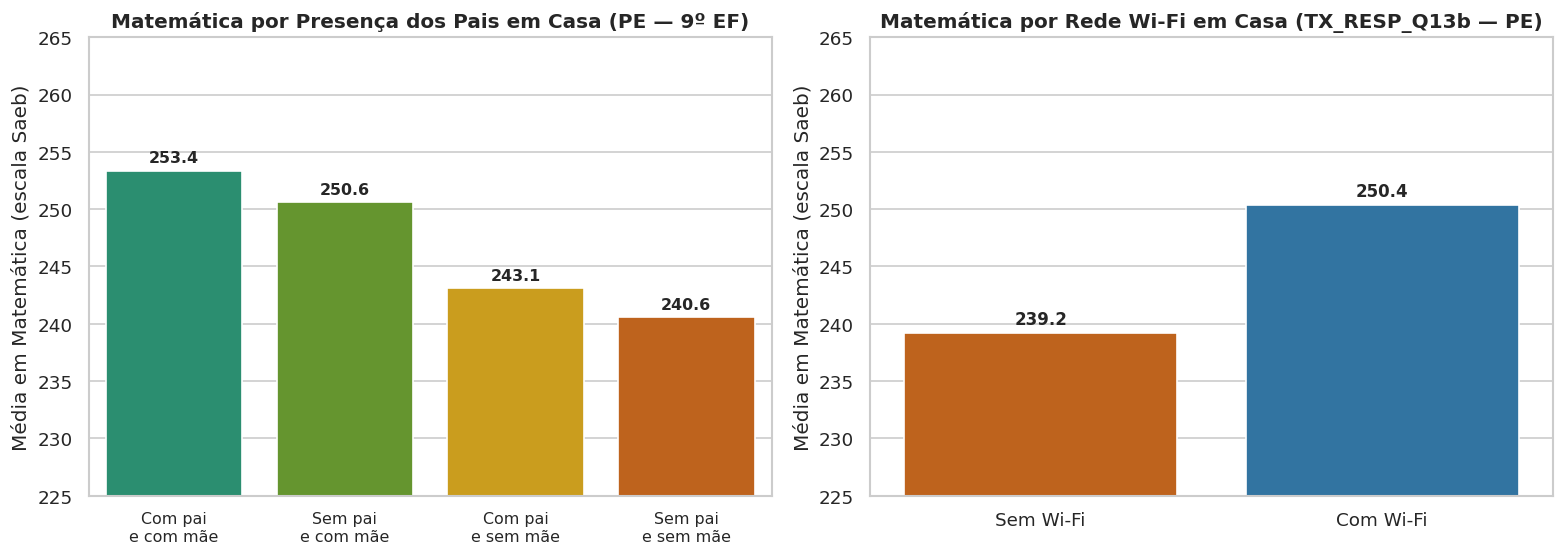

In [47]:
# 5.1 Presença dos pais em casa (TX_RESP_Q07a × TX_RESP_Q07b)
df_q07 = df[mask_q07_valido & df["PROFICIENCIA_MT_SAEB"].notna()].copy()
q07a_sim = df_q07["TX_RESP_Q07a"] == "B"
q07b_sim = df_q07["TX_RESP_Q07b"] == "B"

labels_4 = [
    "Com pai e com mãe",
    "Sem pai e com mãe",
    "Com pai e sem mãe",
    "Sem pai e sem mãe",
]
df_q07["Arranjo"] = np.select(
    [q07a_sim & q07b_sim, q07a_sim & (~q07b_sim), (~q07a_sim) & q07b_sim, (~q07a_sim) & (~q07b_sim)],
    labels_4, default="Outro"
)
df_q07["Sem_Ambos"] = ((~q07a_sim) & (~q07b_sim)).astype(int)
df_q07["Nao_Mora_Com_Ambos"] = (~(q07a_sim & q07b_sim)).astype(int)
df_q07["Sem_Pai"] = (~q07b_sim).astype(int)

comp_arranjo = (
    df_q07.groupby("Arranjo")
    .agg(
        N_alunos=("ID_ALUNO", "count"),
        Media_MT=("PROFICIENCIA_MT_SAEB", "mean"),
        Mediana_MT=("PROFICIENCIA_MT_SAEB", "median"),
        DP_MT=("PROFICIENCIA_MT_SAEB", "std"),
    )
    .reindex(labels_4)
    .reset_index()
)
comp_arranjo["% do total"] = (comp_arranjo["N_alunos"] / comp_arranjo["N_alunos"].sum() * 100).round(1)
comp_arranjo[["Media_MT", "Mediana_MT", "DP_MT"]] = comp_arranjo[["Media_MT", "Mediana_MT", "DP_MT"]].round(2)
comp_arranjo = comp_arranjo[["Arranjo", "N_alunos", "% do total", "Media_MT", "Mediana_MT", "DP_MT"]]

# 5.2 Comparação por Rede Wi-Fi em casa (TX_RESP_Q13b)
df_wifi = df[df["TX_RESP_Q13b"].isin(["A", "B"]) & df["PROFICIENCIA_MT_SAEB"].notna()].copy()
df_wifi["WiFi"] = df_wifi["TX_RESP_Q13b"].map({"A": "Sem Wi-Fi", "B": "Com Wi-Fi"})
comp_wifi = (
    df_wifi.groupby("WiFi")
    .agg(
        N_validos=("ID_ALUNO", "count"),
        Media_MT=("PROFICIENCIA_MT_SAEB", "mean"),
        Mediana_MT=("PROFICIENCIA_MT_SAEB", "median"),
        Min_MT=("PROFICIENCIA_MT_SAEB", "min"),
        Max_MT=("PROFICIENCIA_MT_SAEB", "max"),
    )
    .round(2).reindex(["Sem Wi-Fi", "Com Wi-Fi"]).reset_index()
)

print("=== Matemática por Presença dos Pais em Casa (TX_RESP_Q07a × TX_RESP_Q07b) ===")
display(comp_arranjo)
print("\n=== Matemática por Rede Wi-Fi em Casa (TX_RESP_Q13b) ===")
display(comp_wifi)

# Gráfico 1: Presença dos Pais em Casa (4 opções) + Rede Wi-Fi em Casa (TX_RESP_Q13b)
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), dpi=120)

palette_4 = ["#1b9e77", "#66a61e", "#e6ab02", "#d95f02"]
sns.barplot(data=comp_arranjo, x="Arranjo", y="Media_MT", palette=palette_4, ax=axes[0])
axes[0].set_title("Matemática por Presença dos Pais em Casa (PE — 9º EF)", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Média em Matemática (escala Saeb)")
axes[0].set_xticklabels(["Com pai\ne com mãe", "Sem pai\ne com mãe", "Com pai\ne sem mãe", "Sem pai\ne sem mãe"], fontsize=9.5)
axes[0].set_ylim(225, 265)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.1f", fontsize=9.5, fontweight="bold", padding=3)

sns.barplot(data=comp_wifi, x="WiFi", y="Media_MT", palette=["#d95f02", "#1f78b4"], ax=axes[1])
axes[1].set_title("Matemática por Rede Wi-Fi em Casa (TX_RESP_Q13b — PE)", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Média em Matemática (escala Saeb)")
axes[1].set_ylim(225, 265)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f", fontsize=10, fontweight="bold", padding=3)

plt.tight_layout()
fig1_path = os.path.join(DIR_SAIDAS, "evidencia_saeb_PE_2023.png")
plt.savefig(fig1_path, dpi=150, bbox_inches="tight")
plt.show()

=== Matemática, % Wi-Fi e % Ausência Parental por Nível do INSE (PE, IN_INSE = 1) ===


,NU_TIPO_NIVEL_INSE,N_alunos,Media_MT,Pct_WiFi,Pct_Sem_Pai_e_Sem_Mae,Pct_Sem_Pai
0,1,2077,238.75,27.24,11.80,41.26
1,2,17054,244.18,79.53,10.21,41.08
2,3,21134,247.99,94.11,9.38,35.91
3,4,20157,252.36,96.77,8.57,28.56
4,5,12342,258.20,98.15,7.55,22.23
5,6,5599,263.05,98.99,7.97,19.86
6,7,2503,273.14,99.40,6.87,17.62
7,8,255,287.52,100.00,6.27,13.73



=== Matemática por Nível do INSE × 4 Opções de Presença dos Pais em Casa ===


Arranjo,Com pai e com mãe,Sem pai e com mãe,Com pai e sem mãe,Sem pai e sem mãe
NU_TIPO_NIVEL_INSE,,,,
1,241.73,237.67,240.83,226.96
2,244.98,246.81,238.11,234.07
3,248.62,250.09,240.03,240.86
4,253.78,252.65,244.79,243.12
5,259.75,258.31,249.30,246.00
6,264.92,262.70,254.90,248.68
7,276.27,272.25,253.10,247.78
8,294.69,240.14,256.12,254.92



=== Correlação de Spearman com Matemática (PE, Saeb 2023) ===


,Matemática
NU_TIPO_NIVEL_INSE (1-8),0.140
Mora com mãe/madrasta (Q07a),0.077
Rede Wi-Fi em casa (Q13b),0.060
Mora com pai/padrasto (Q07b),0.048
Sem pai e sem mãe,-0.070


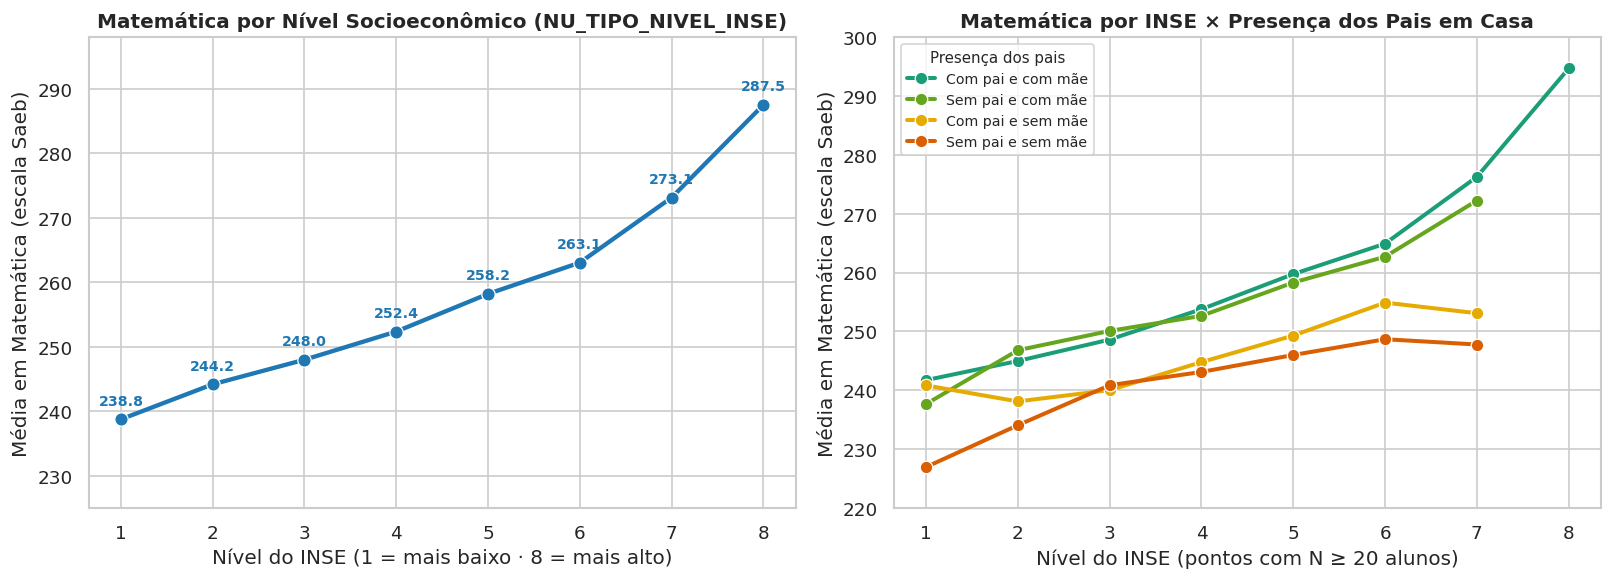

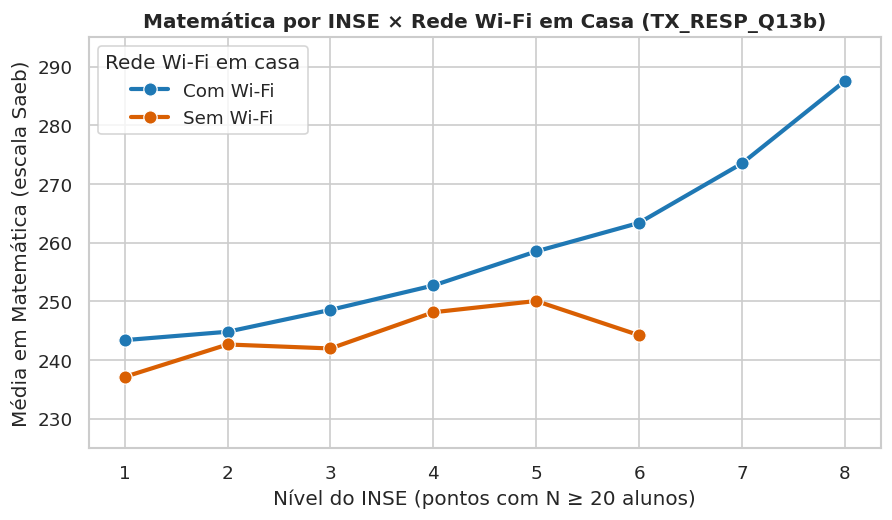

In [48]:
# Base limpa de INSE (IN_INSE == 1) + Q07a/Q07b válidos + Proficiência MT válida
df_inse = df_q07[df_q07["IN_INSE"] == 1].copy()
df_inse["NU_TIPO_NIVEL_INSE"] = df_inse["NU_TIPO_NIVEL_INSE"].astype(int)
df_inse["Tem_WiFi"] = df_inse["TX_RESP_Q13b"].map({"A": 0, "B": 1})

# 6.1 Resumo por Nível do INSE (1 a 8) incluindo % Wi-Fi e % ausência parental
resumo_inse = (
    df_inse.groupby("NU_TIPO_NIVEL_INSE")
    .agg(
        N_alunos=("ID_ALUNO", "count"),
        Media_MT=("PROFICIENCIA_MT_SAEB", "mean"),
        Pct_WiFi=("Tem_WiFi", lambda s: s.mean() * 100),
        Pct_Sem_Pai_e_Sem_Mae=("Sem_Ambos", lambda s: s.mean() * 100),
        Pct_Sem_Pai=("Sem_Pai", lambda s: s.mean() * 100),
    )
    .round(2)
    .reset_index()
)

# 6.2 Cruzamento: Nível do INSE × todas as 4 opções de presença dos pais
cruz_inse_pais = (
    df_inse.groupby(["NU_TIPO_NIVEL_INSE", "Arranjo"])
    .agg(N=("ID_ALUNO", "count"), Media_MT=("PROFICIENCIA_MT_SAEB", "mean"))
    .round(2)
    .reset_index()
)
pivot_pais_mt = cruz_inse_pais.pivot(index="NU_TIPO_NIVEL_INSE", columns="Arranjo", values="Media_MT")[labels_4]

# 6.3 Correlação de Spearman (exploratória) das 4 explicativas com Matemática
df_corr = pd.DataFrame({
    "NU_TIPO_NIVEL_INSE (1-8)": df_inse["NU_TIPO_NIVEL_INSE"],
    "Mora com mãe/madrasta (Q07a)": (df_inse["TX_RESP_Q07a"] == "B").astype(int),
    "Rede Wi-Fi em casa (Q13b)": df_inse["Tem_WiFi"],
    "Mora com pai/padrasto (Q07b)": (df_inse["TX_RESP_Q07b"] == "B").astype(int),
    "Sem pai e sem mãe": df_inse["Sem_Ambos"],
    "Matemática": df_inse["PROFICIENCIA_MT_SAEB"],
}).corr(method="spearman")[["Matemática"]].drop("Matemática").round(3)

print("=== Matemática, % Wi-Fi e % Ausência Parental por Nível do INSE (PE, IN_INSE = 1) ===")
display(resumo_inse)
print("\n=== Matemática por Nível do INSE × 4 Opções de Presença dos Pais em Casa ===")
display(pivot_pais_mt)
print("\n=== Correlação de Spearman com Matemática (PE, Saeb 2023) ===")
display(df_corr)

# Gráfico 2: Gradiente do INSE (MT) + Cruzamento INSE × 4 opções de presença dos pais
fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.0), dpi=120)

sns.lineplot(data=resumo_inse, x="NU_TIPO_NIVEL_INSE", y="Media_MT",
             marker="o", linewidth=2.6, markersize=8, color="#1f78b4", ax=axes[0])
axes[0].set_title("Matemática por Nível Socioeconômico (NU_TIPO_NIVEL_INSE)", fontweight="bold")
axes[0].set_xlabel("Nível do INSE (1 = mais baixo · 8 = mais alto)")
axes[0].set_ylabel("Média em Matemática (escala Saeb)")
axes[0].set_xticks(range(1, 9))
axes[0].set_ylim(225, 298)
for _, r in resumo_inse.iterrows():
    axes[0].text(r["NU_TIPO_NIVEL_INSE"], r["Media_MT"] + 2.2, f"{r['Media_MT']:.1f}",
                 ha="center", fontsize=8.5, color="#1f78b4", fontweight="bold")

cruz_plot = cruz_inse_pais[cruz_inse_pais["N"] >= 20].copy()
palette_map = {
    "Com pai e com mãe": "#1b9e77",
    "Sem pai e com mãe": "#66a61e",
    "Com pai e sem mãe": "#e6ab02",
    "Sem pai e sem mãe": "#d95f02",
}
sns.lineplot(data=cruz_plot,
             x="NU_TIPO_NIVEL_INSE", y="Media_MT", hue="Arranjo", hue_order=labels_4,
             marker="o", linewidth=2.4, markersize=7.5, palette=palette_map, ax=axes[1])
axes[1].set_title("Matemática por INSE × Presença dos Pais em Casa", fontweight="bold")
axes[1].set_xlabel("Nível do INSE (pontos com N ≥ 20 alunos)")
axes[1].set_ylabel("Média em Matemática (escala Saeb)")
axes[1].set_xticks(range(1, 9))
axes[1].set_ylim(220, 300)
axes[1].legend(title="Presença dos pais", loc="upper left", fontsize=8.5, title_fontsize=9)

plt.tight_layout()
fig2_path = os.path.join(DIR_SAIDAS, "evidencia_inse_arranjo_PE_2023.png")
plt.savefig(fig2_path, dpi=150, bbox_inches="tight")
plt.show()

# Gráfico 3: Matemática por INSE × Rede Wi-Fi em Casa (TX_RESP_Q13b)
df_inse_wifi = df_inse[df_inse["Tem_WiFi"].notna()].copy()
df_inse_wifi["WiFi"] = df_inse_wifi["Tem_WiFi"].map({0.0: "Sem Wi-Fi", 1.0: "Com Wi-Fi"})
cruz_inse_wifi = (
    df_inse_wifi.groupby(["NU_TIPO_NIVEL_INSE", "WiFi"])
    .agg(N=("ID_ALUNO", "count"), Media_MT=("PROFICIENCIA_MT_SAEB", "mean"))
    .round(2)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7.6, 4.5), dpi=120)
sns.lineplot(data=cruz_inse_wifi[cruz_inse_wifi["N"] >= 20],
             x="NU_TIPO_NIVEL_INSE", y="Media_MT", hue="WiFi", hue_order=["Com Wi-Fi", "Sem Wi-Fi"],
             marker="o", linewidth=2.5, markersize=8, palette=["#1f78b4", "#d95f02"], ax=ax)
ax.set_title("Matemática por INSE × Rede Wi-Fi em Casa (TX_RESP_Q13b)", fontweight="bold")
ax.set_xlabel("Nível do INSE (pontos com N ≥ 20 alunos)")
ax.set_ylabel("Média em Matemática (escala Saeb)")
ax.set_xticks(range(1, 9))
ax.set_ylim(225, 295)
ax.legend(title="Rede Wi-Fi em casa", loc="upper left")

plt.tight_layout()
fig3_path = os.path.join(DIR_SAIDAS, "evidencia_inse_wifi_PE_2023.png")
plt.savefig(fig3_path, dpi=150, bbox_inches="tight")
plt.show()

---
## 4. Achado, Dúvida e Limites Metodológicos

- **Achado:** No recorte de **Pernambuco** (Saeb 2023, 9º ano EF, `N = 109.542` estudantes em `1.450` escolas):
  1. **Presença dos pais em casa (`N = 84.457` válidos em `Q07a`, `Q07b` e MT):** **65,2%** moram com pai e mãe (`253,36` pts em Matemática), **22,5%** sem pai e com mãe (`250,62`), **3,3%** com pai e sem mãe (`243,12`) e **9,0%** sem pai e sem mãe (`240,60` — diferença de **−12,76 pts** frente a quem mora com ambos).
  2. **Conectividade domiciliar (`TX_RESP_Q13b`):** **91,0%** têm Wi-Fi em casa (`N = 90.322` válidos); estudantes com Wi-Fi pontuam **+11,20 pontos** a mais em Matemática (`250,38` vs. `239,18`; `N = 81.922` e `8.147`).
  3. **Nível Socioeconômico (`NU_TIPO_NIVEL_INSE`, filtrado por `IN_INSE = 1`):** do Nível 1 ao Nível 8, a média de Matemática sobe de **`238,75`** para **`287,52`** (**+48,77 pts**), enquanto o acesso a Wi-Fi sobe de **27,2%** para **100,0%**. Mesmo dentro do mesmo nível do INSE, os grupos *Com pai e sem mãe* e *Sem pai e sem mãe* permanecem consistentemente abaixo dos grupos que moram com a mãe.
- **Dúvida:** Ao aplicar os pesos amostrais (`PESO_ALUNO_MT`) e controlar simultaneamente por `NU_TIPO_NIVEL_INSE`, `ID_LOCALIZACAO` (Urbana/Rural) e `TX_RESP_Q13b` (Wi-Fi), quanto da diferença em Matemática permanece associada à ausência dos pais em casa e quanto se explica por vulnerabilidade socioeconômica e de acesso?
- **Limites e alcance dos cálculos:** (1) Diferenças entre grupos **não provam causalidade**; (2) `TX_RESP_Q07a`/`Q07b` medem **coabitação** (incluindo madrasta/padrasto) e não o estado civil dos pais; (3) médias simples e contagens descrevem apenas o recorte — estimativas populacionais oficiais exigem `PESO_ALUNO_MT` e critérios de inclusão; (4) o mascaramento LGPD de `ID_ESCOLA`/`ID_MUNICIPIO` (`6...`) impede cruzar diretamente o estudante com a mesma escola no Censo Escolar 2023.

---
## 5. Duas Perguntas para Continuar

1. ⭐ **[PRIORIDADE] Contexto familiar, conectividade e desempenho em Matemática:**
   - **Pergunta:** *Como varia a proficiência em Matemática (`PROFICIENCIA_MT_SAEB`) entre os quatro perfis de presença dos pais em casa (`TX_RESP_Q07a`, `TX_RESP_Q07b`) e acesso a Wi-Fi (`TX_RESP_Q13b`) dentro de cada faixa do `NU_TIPO_NIVEL_INSE` no 9º ano de Pernambuco, aplicando o peso amostral (`PESO_ALUNO_MT`)?*
   - **Motivação:** Verificar se o efeito da ausência parental e da falta de Wi-Fi sobre Matemática se mantém após ponderar a amostra e controlar pelo nível socioeconômico.
   - **Recorte / Variáveis / Fonte:** PE, 9º ano EF, Saeb 2023 (`IN_SITUACAO_CENSO = 1`, `IN_INSE = 1`) · `TX_RESP_Q07a`, `TX_RESP_Q07b`, `TX_RESP_Q13b`, `NU_TIPO_NIVEL_INSE`, `PROFICIENCIA_MT_SAEB`, `PESO_ALUNO_MT` · Fonte: `TS_ALUNO_9EF.csv` (Saeb 2023).
2. **Aprofundamento territorial (Urbana vs. Rural) e conexão com o Censo Escolar:**
   - **Pergunta:** *A desigualdade de Matemática associada à falta de Wi-Fi em casa (`TX_RESP_Q13b`) e ao nível socioeconômico (`NU_TIPO_NIVEL_INSE`) é mais acentuada nas escolas rurais do que nas urbanas em Pernambuco, e como esse cenário dialoga com a infraestrutura escolar mapeada no Censo Escolar 2023?*
   - **Motivação:** Conectar a *Escada Tecnológica* do Censo Escolar (infraestrutura da escola) ao contexto domiciliar e ao desempenho medido no Saeb.
   - **Recorte / Variáveis / Fonte:** PE, 9º ano EF, 2023 · `ID_LOCALIZACAO`/`TP_LOCALIZACAO`, `IN_PUBLICA`/`TP_DEPENDENCIA`, `TX_RESP_Q13b`, `NU_TIPO_NIVEL_INSE`, `PROFICIENCIA_MT_SAEB` · Fontes: `TS_ALUNO_9EF.csv` (Saeb 2023) e `microdados_ed_basica_2023.csv` (Censo Escolar 2023).
   - **Pendência para uso combinado das duas bases:** conferir alinhamento do ano (`2023`), nível de análise (escola no Censo vs. estudante no Saeb) e compatibilidade de chaves — como `ID_ESCOLA` e `ID_MUNICIPIO` são mascarados no Saeb, a comparação entre bases deve ser feita apenas em níveis agregados compatíveis (UF, localização Urbana/Rural e rede Pública/Privada).

- **Justificativa da prioridade:** A **Pergunta 1** usa integralmente uma única base (`TS_ALUNO_9EF.csv`), responde diretamente ao achado central (presença dos pais + Wi-Fi + INSE em Matemática) e evita o bloqueio de chaves mascaradas entre Saeb e Censo.
- **Primeira ação:** Validar o cálculo ponderado com `PESO_ALUNO_MT` por faixa de `NU_TIPO_NIVEL_INSE`, auditar o perfil das ausências em `Q07a`/`Q07b`/`Q13b` (especialmente em escolas rurais) e testar um modelo descritivo de regressão ponderada.

In [49]:
# 8.1 Exportar planilha Excel completa para a pasta da equipe na nuvem
df_vars = pd.DataFrame([
    ("TX_RESP_Q07a", "Mora na casa: Mãe(s) ou madrasta(s)", "A=Não; B=Sim | Especiais: .=Branco, *=Nulo, NaN"),
    ("TX_RESP_Q07b", "Mora na casa: Pai(s) ou padrasto(s)", "A=Não; B=Sim | Especiais: .=Branco, *=Nulo, NaN"),
    ("TX_RESP_Q13b", "Na sua casa tem: Rede Wi-Fi", "A=Não; B=Sim | Especiais: .=Branco, *=Nulo, NaN"),
    ("NU_TIPO_NIVEL_INSE", "Classificação do INSE em 8 grupos (Nível I a VIII)", "1 a 8 (filtrar IN_INSE=1; IN_INSE=0 é ausência/não calculado)"),
    ("PROFICIENCIA_MT_SAEB", "Proficiência em Matemática (escala Saeb)", "Numérico contínuo (média 250, DP 50) | Especial: NaN"),
], columns=["Coluna escolhida", "O que registra", "Valores válidos e códigos especiais"])

excel_path = os.path.join(DIR_SAIDAS, "planilha_analise_saeb_2023_PE.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    ficha.to_excel(writer, sheet_name="Ficha_Recorte_PE", index=False)
    df_vars.to_excel(writer, sheet_name="Cinco_Variaveis", index=False)
    df_cat.to_excel(writer, sheet_name="Frequencias_Categoricas", index=False)
    df_prof.to_excel(writer, sheet_name="Resumo_Matematica", index=False)
    comp_arranjo.to_excel(writer, sheet_name="Presenca_Pais_MT", index=False)
    comp_wifi.to_excel(writer, sheet_name="Comparacao_WiFi_MT", index=False)
    resumo_inse.to_excel(writer, sheet_name="Resumo_INSE_Niveis", index=False)
    cruz_inse_pais.to_excel(writer, sheet_name="INSE_x_Presenca_Pais", index=False)
    df_corr.reset_index().to_excel(writer, sheet_name="Correlacoes_Spearman", index=False)

# 8.2 Gerar o Registro da Equipe (1 página) atualizado conforme Etapa 6 do Roteiro
registro_md = f"""# Registro da Equipe — Oficina de Exploração do Saeb 2023

**Integrantes:** _(preencher nomes da equipe)_  
**Edição e Recorte:** Saeb 2023 · 9º ano do Ensino Fundamental (`TS_ALUNO_9EF.csv`) · **Pernambuco (PE, `ID_UF = 26`)** · **{len(df):,} estudantes** em **{df['ID_ESCOLA'].nunique():,} escolas** e **{df['ID_MUNICIPIO'].nunique():,} municípios mascarados** (`1 linha = 1 estudante`).

---

## 1. As 5 Variáveis e Primeira Evidência (PE — Saeb 2023)

| Coluna | O que registra | Resumo no Recorte (PE) | Ausências / Códigos Especiais |
|---|---|---|---|
| `TX_RESP_Q07a` | Mora com mãe ou madrasta | **Sim:** 87,9% · **Não:** 12,1% _(válidos = 90.355)_ | Branco (`.`): 18.297 · Nulo (`*`): 890 |
| `TX_RESP_Q07b` | Mora com pai ou padrasto | **Sim:** 68,5% · **Não:** 31,5% _(válidos = 86.232)_ | Branco (`.`): 22.820 · Nulo (`*`): 490 |
| `TX_RESP_Q13b` | Rede Wi-Fi em casa | **Sim:** 91,0% · **Não:** 9,0% _(válidos = 90.322)_ | Branco (`.`): 18.642 · Nulo (`*`): 578 |
| `NU_TIPO_NIVEL_INSE` | Nível Socioeconômico (1 a 8) | Concentração nos Níveis II–V (87,2%) _(válidos `IN_INSE=1` = 91.362)_ | `IN_INSE = 0` (não calculado): 18.180 |
| `PROFICIENCIA_MT_SAEB` | Proficiência em Matemática | **N válidos:** 96.313 · **Média:** 248,59 · **Mín:** 108,84 · **Máx:** 419,96 _(ponderada: 255,14)_ | Ausentes (`NaN`): 13.229 (12,1%) |

- **Presença dos pais × Matemática (`N = 84.457`):** Com pai e com mãe = **253,36** (65,2%) · Sem pai e com mãe = **250,62** (22,5%) · Com pai e sem mãe = **243,12** (3,3%) · Sem pai e sem mãe = **240,60** (9,0%; **−12,76 pts**).
- **Wi-Fi em casa × Matemática:** Com Wi-Fi = **250,38** (`N = 81.922`) vs. Sem Wi-Fi = **239,18** (`N = 8.147`) → **+11,20 pts**.

---

## 2. Achado, Dúvida e Limites
- **Achado:** Em Pernambuco (Saeb 2023, 9º ano EF), o nível socioeconômico (`NU_TIPO_NIVEL_INSE`) apresenta o maior gradiente em Matemática (**238,75** no Nível 1 até **287,52** no Nível 8; **+48,77 pts**), seguido pela presença dos pais em casa (**−12,76 pts** para quem não mora com pai nem mãe) e Wi-Fi domiciliar (**+11,20 pts**). Mesmo dentro do mesmo nível do INSE, estudantes sem mãe em casa (*Com pai e sem mãe* e *Sem pai e sem mãe*) mantêm médias inferiores.
- **Dúvida:** Ao aplicar `PESO_ALUNO_MT` e controlar simultaneamente por `NU_TIPO_NIVEL_INSE`, `TX_RESP_Q13b` e localização (`ID_LOCALIZACAO`), quanto da diferença em Matemática permanece associada à ausência parental?
- **Limites:** (1) Diferenças entre grupos não provam causalidade; (2) `Q07a`/`Q07b` medem coabitação (incluem madrasta/padrasto) e não estado civil dos pais; (3) médias simples descrevem o recorte — estimativas populacionais exigem `PESO_ALUNO_MT`; (4) códigos de escola/município no Saeb são mascarados (`6...`, LGPD), impedindo cruzamento direto por escola com o Censo Escolar 2023.

---

## 3. Duas Perguntas para Continuar, Prioridade e Primeira Ação
1. **[PRIORIDADE]** *Como varia a proficiência em Matemática (`PROFICIENCIA_MT_SAEB`) entre os quatro perfis de presença dos pais (`TX_RESP_Q07a`, `TX_RESP_Q07b`) e acesso a Wi-Fi (`TX_RESP_Q13b`) dentro de cada nível do `NU_TIPO_NIVEL_INSE` em PE, usando `PESO_ALUNO_MT`?*  
   - *Motivação / Recorte / Fonte:* Separar o peso do contexto familiar e da conectividade do efeito socioeconômico; PE (9º EF, Saeb 2023, `IN_INSE=1`); fonte: `TS_ALUNO_9EF.csv`.
2. *A desigualdade em Matemática associada à falta de Wi-Fi (`TX_RESP_Q13b`) e ao `NU_TIPO_NIVEL_INSE` é maior na zona rural que na urbana em PE, e como isso dialoga com a infraestrutura escolar do Censo Escolar 2023?*  
   - *Motivação / Recorte / Fonte:* Conectar a *Escada Tecnológica* do Censo ao Saeb; PE (2023); fontes: `TS_ALUNO_9EF.csv` e `microdados_ed_basica_2023.csv`. *Pendência de compatibilidade:* comparar apenas por agregações compatíveis (UF, Urbana/Rural, Pública/Privada), pois `ID_ESCOLA` e `ID_MUNICIPIO` são mascarados no Saeb.

- **Justificativa da prioridade:** A Pergunta 1 usa uma única base (`TS_ALUNO_9EF.csv`), testa diretamente as 5 variáveis escolhidas com peso amostral e independe do cruzamento de chaves mascaradas.
- **Primeira ação:** Validar o cálculo ponderado com `PESO_ALUNO_MT` por faixa de `NU_TIPO_NIVEL_INSE` e auditar o perfil das não respostas em `Q07a`, `Q07b` e `Q13b`.
"""

reg_path = os.path.join(DIR_SAIDAS, "registro_equipe_1_pagina_PE.md")
with open(reg_path, "w", encoding="utf-8") as f:
    f.write(registro_md)

print("Planilha final salva em:", excel_path)
print("Registro de 1 página salvo em:", reg_path)

Planilha final salva em: /home/jorge/Documentos/Faculdade/Materias-Faculdade/mineracao-educacional/oficina_saeb_2023/saidas/planilha_analise_saeb_2023_PE.xlsx
Registro de 1 página salvo em: /home/jorge/Documentos/Faculdade/Materias-Faculdade/mineracao-educacional/oficina_saeb_2023/saidas/registro_equipe_1_pagina_PE.md
